In [30]:
# import modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy import stats
import statsmodels.api as sm

# Modules for Generate Y-Data Profile
from ydata_profiling import ProfileReport
from ydata_profiling.config import Settings


In [31]:
# Load and read the dataset
df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [32]:
# Read the data columns and their types
df.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

In [33]:
# Need to rename the "Target" as "Heart_Disease"
df = df.rename(columns={"target": "Heart_Disease"})
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Heart_Disease
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [34]:
# Save the fixed dataset as a new CSV file
df.to_csv("Heart_Disease_fixed.csv", index=False)

### Generate Y-Data Profiling with Extra Features for more Data Analysis

In [35]:
df = pd.read_csv('Heart_Disease_fixed.csv')

# Create configuration
config = Settings()

# Set the skewness threshold to whichever you prefer.
config.vars.num.skewness_threshold = 2

# Enable correlations
config.correlations["pearson"].calculate = True
config.correlations["phi_k"].calculate = True

# Generate the profile report
report = ProfileReport(
    df,
    title='Heart Disease, Data Engineering / Advanced Data Analytics, 2026',
    config=config
)

# Save report
report.to_file("ydata_report_classification_extra_features.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 14/14 [00:00<00:00, 88.33it/s]


KeyboardInterrupt: 

### Generate data quality suggestions with AutoViz

In [ ]:
from autoviz.AutoViz_Class import AutoViz_Class
AV = AutoViz_Class()
report = AV.AutoViz("Heart_Disease_fixed.csv")

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (303, 14)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  1
    Number of Integer-Categorical Columns =  9
    Number of String-Categorical Columns =  0
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Boolean Columns =  4
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  0
    Number of 

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
age,int64,0.000000,13,29.000000,77.000000,No issue
sex,int64,0.000000,0,0.000000,1.000000,No issue
cp,int64,0.000000,1,0.000000,3.000000,No issue
trestbps,int64,0.000000,16,94.000000,200.000000,Column has 9 outliers greater than upper bound (170.00) or lower than lower bound(90.00). Cap them or remove them.
chol,int64,0.000000,50,126.000000,564.000000,Column has 5 outliers greater than upper bound (370.38) or lower than lower bound(115.38). Cap them or remove them.
fbs,int64,0.000000,0,0.000000,1.000000,No issue
restecg,int64,0.000000,0,0.000000,2.000000,No issue
thalach,int64,0.000000,30,71.000000,202.000000,Column has 1 outliers greater than upper bound (215.12) or lower than lower bound(84.12). Cap them or remove them.
exang,int64,0.000000,0,0.000000,1.000000,No issue
oldpeak,float64,0.000000,NA,0.000000,6.200000,Column has 5 outliers greater than upper bound (4.00) or lower than lower bound(-2.40). Cap them or remove them.


All Plots done
Time to run AutoViz = 5 seconds 

 ###################### AUTO VISUALIZATION Completed ########################


### Visualize the Distribution or imbalances using Q-Q Plot

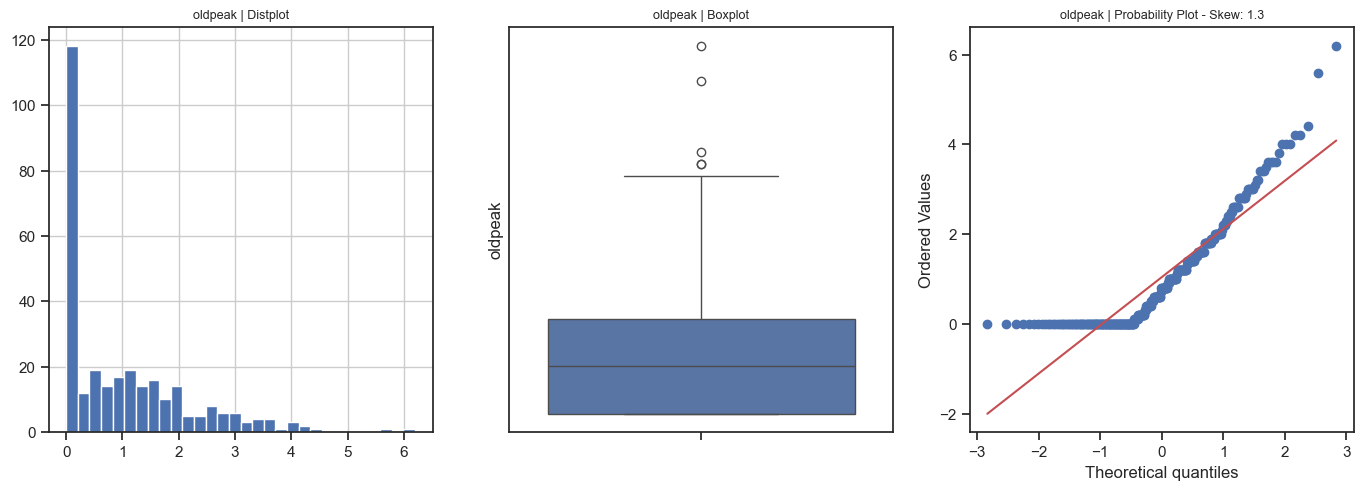

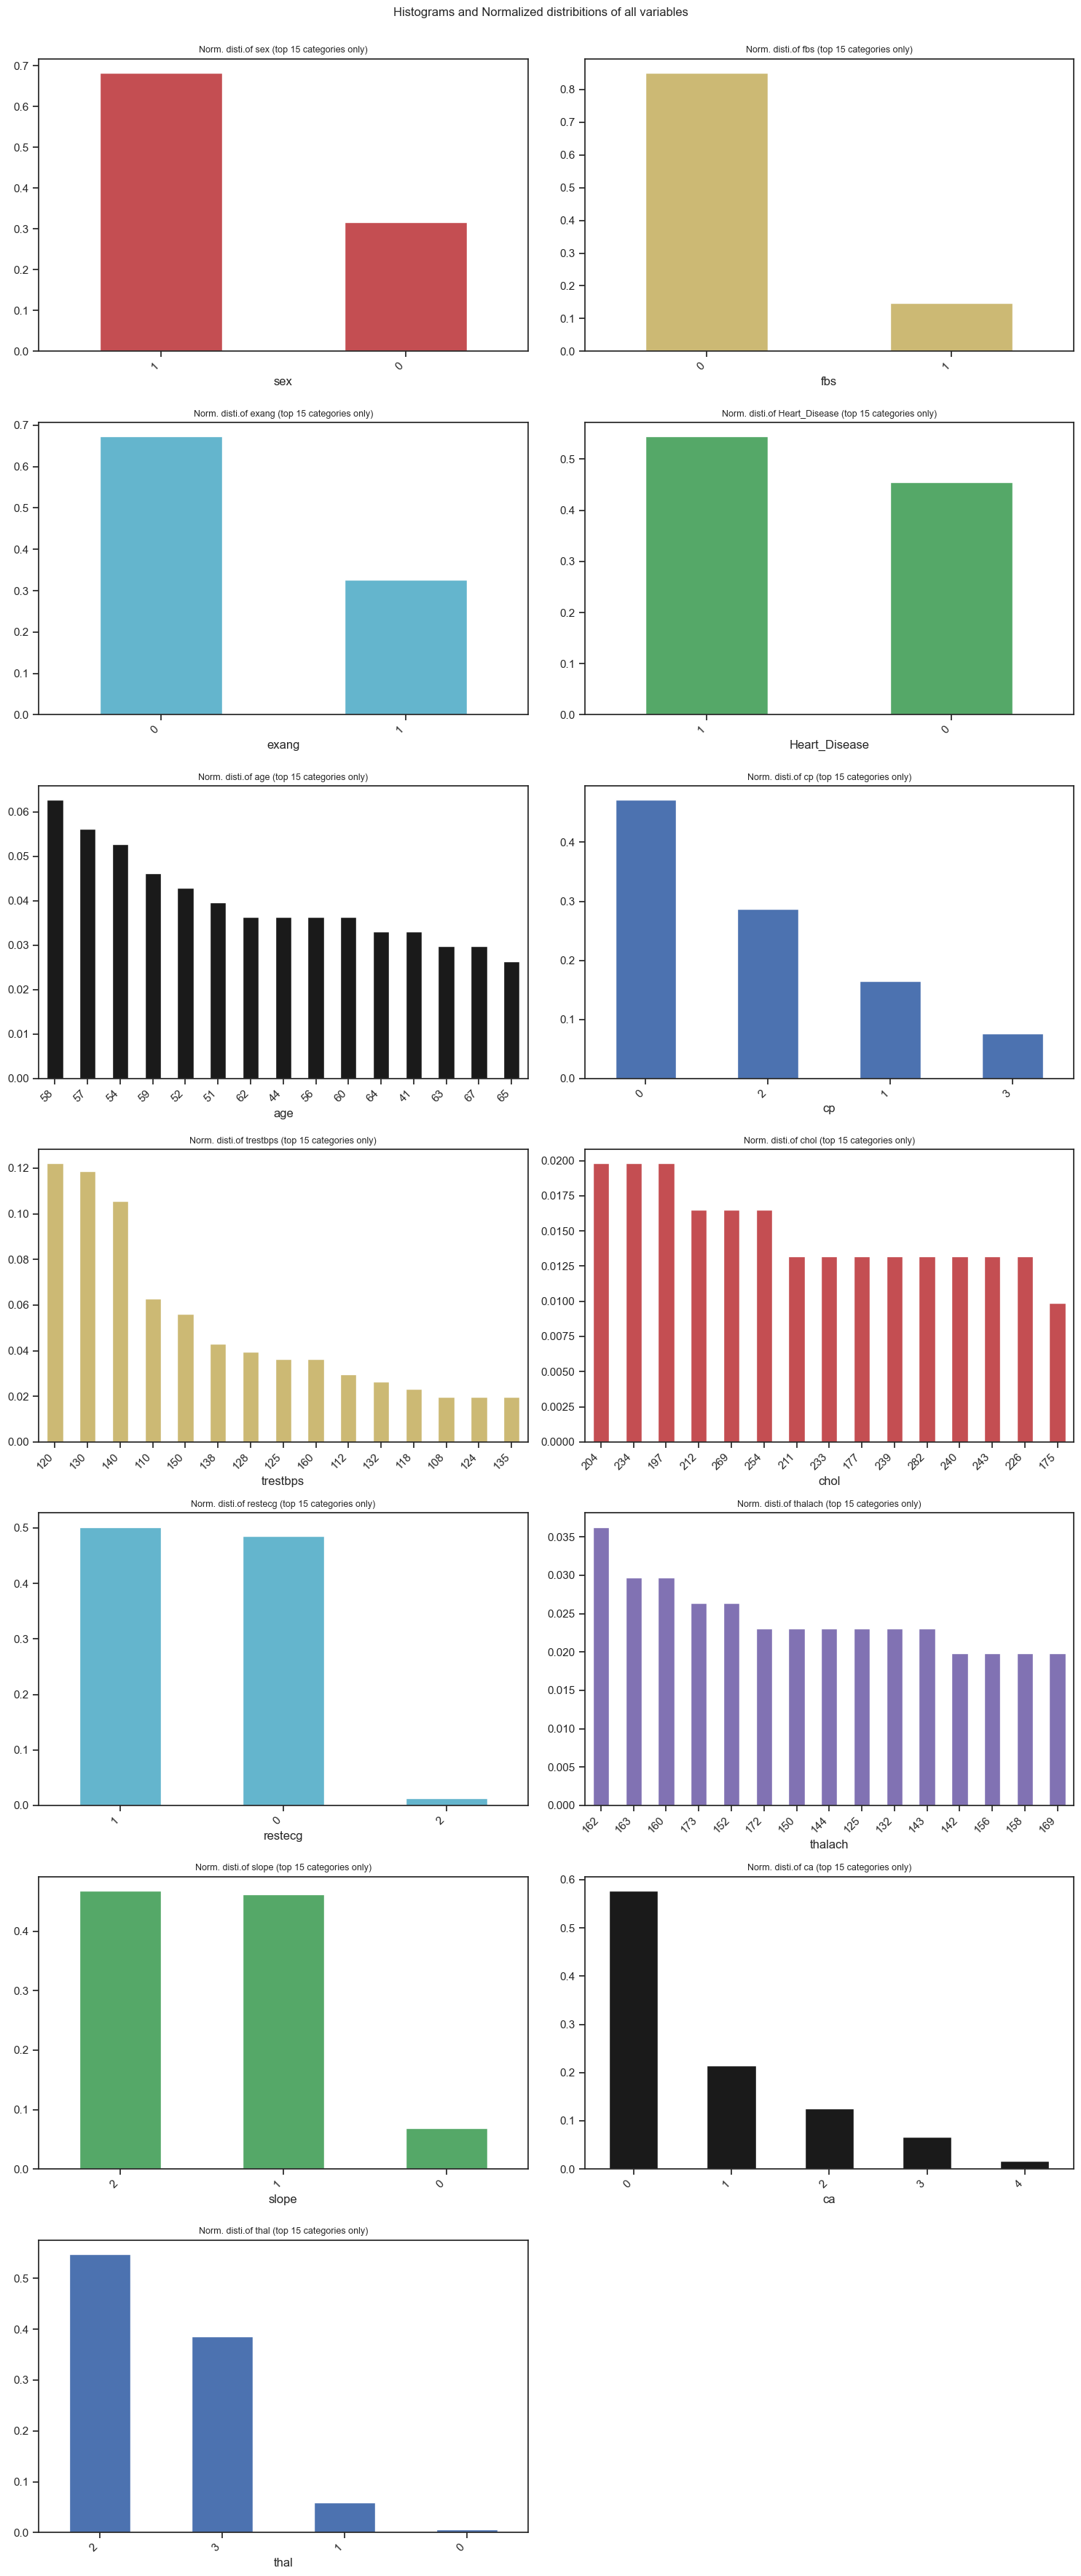

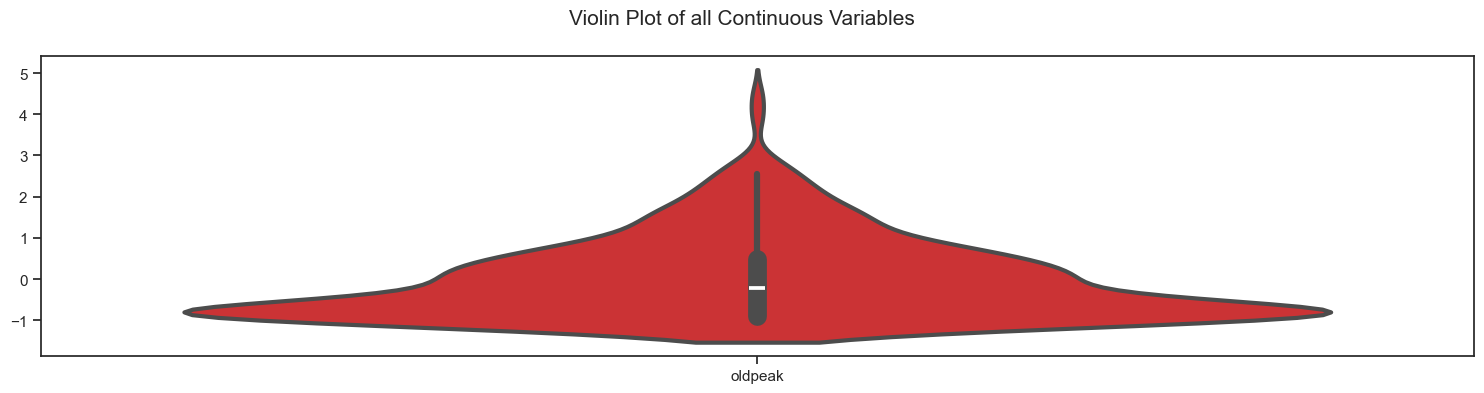

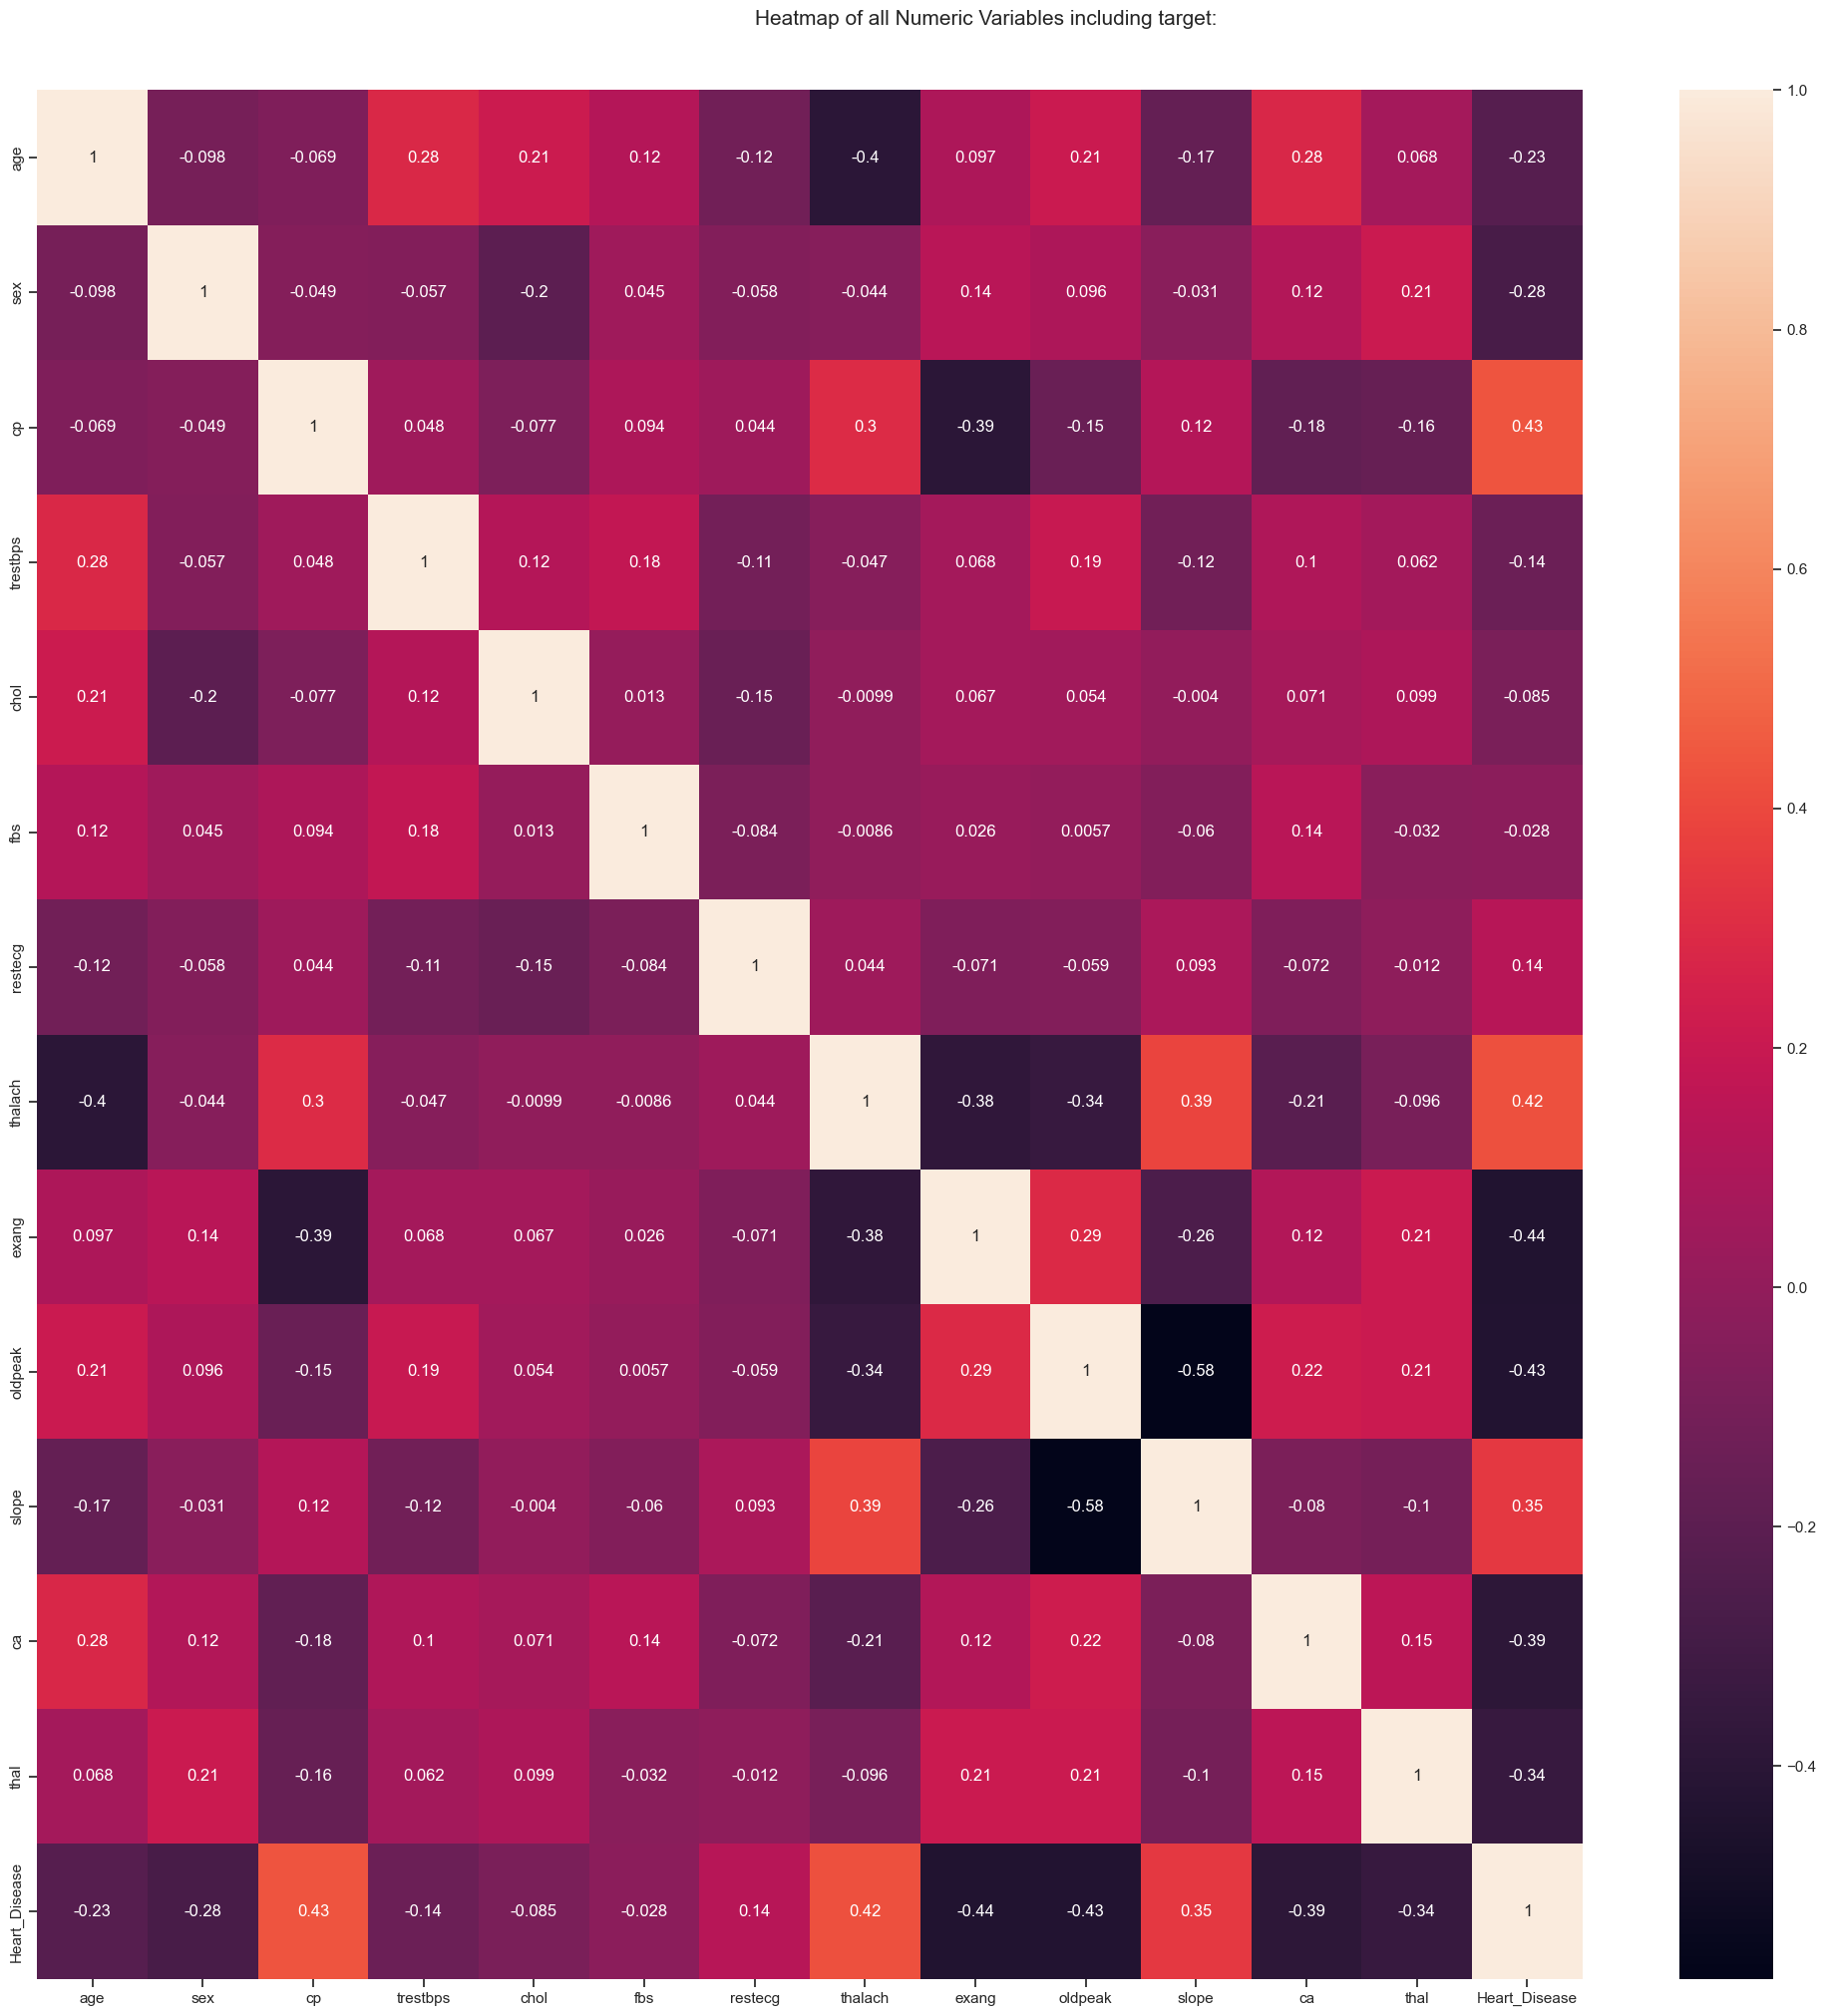

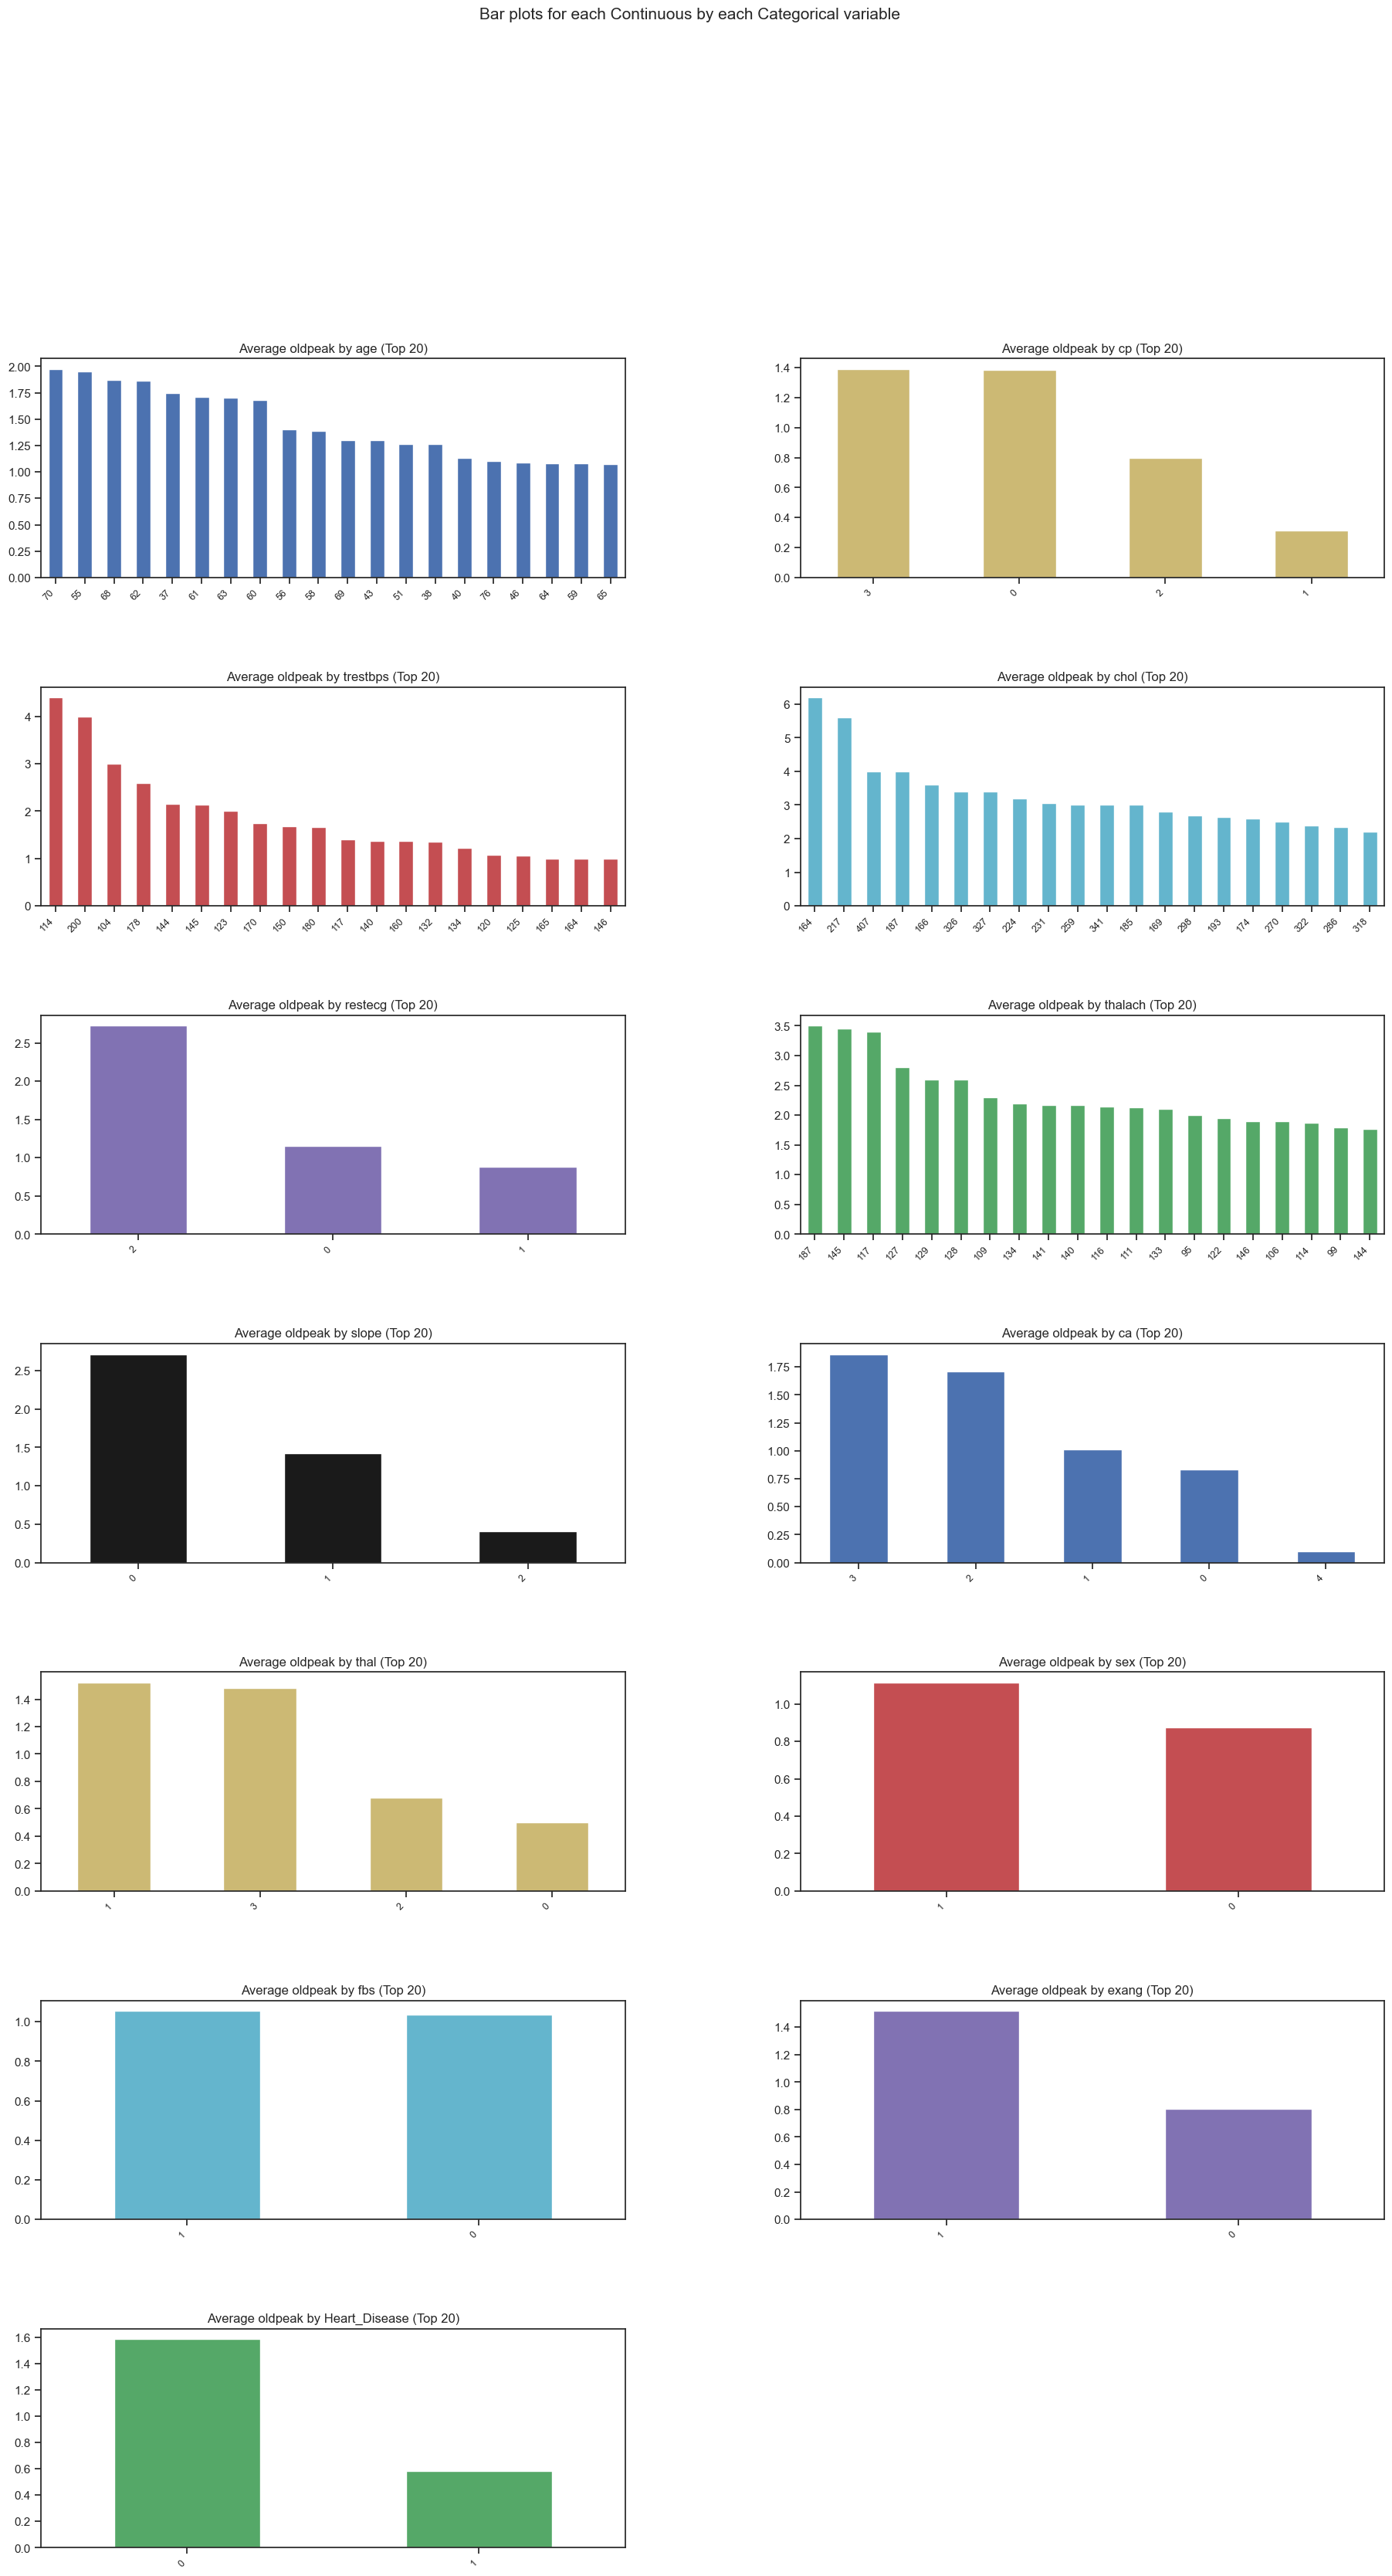

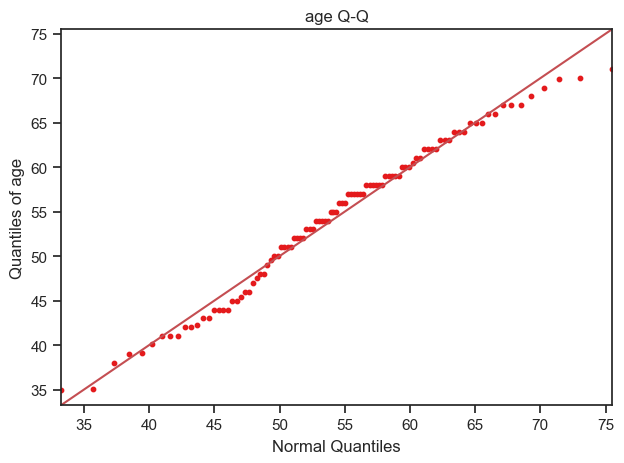

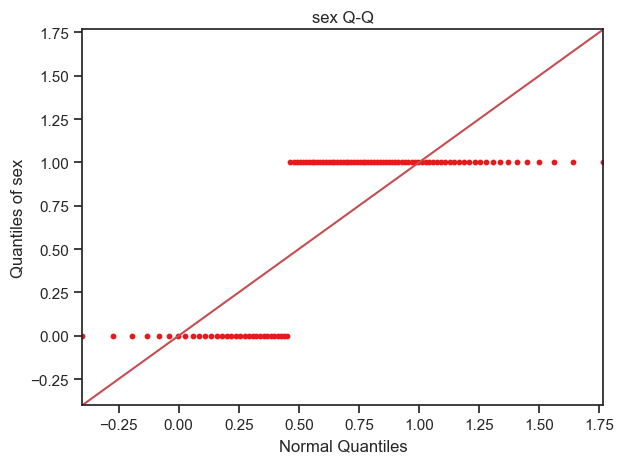

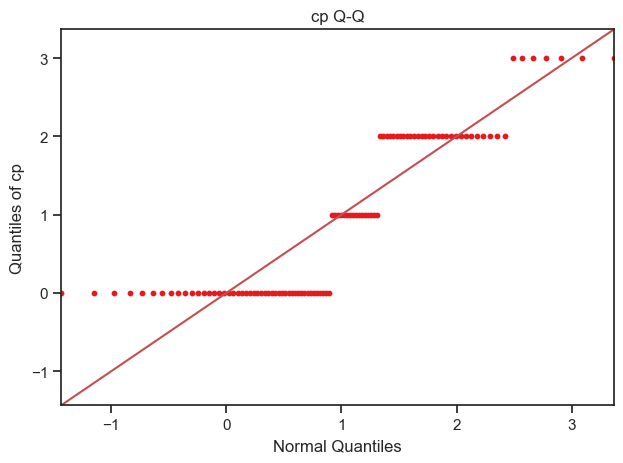

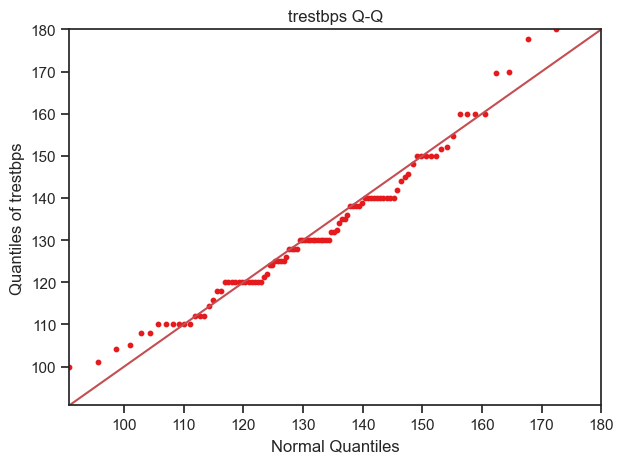

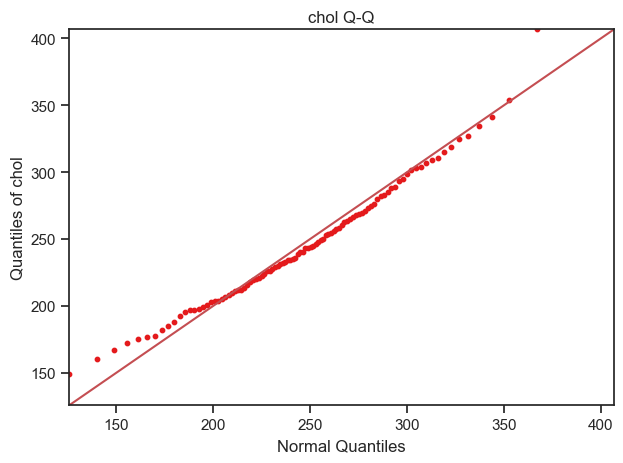

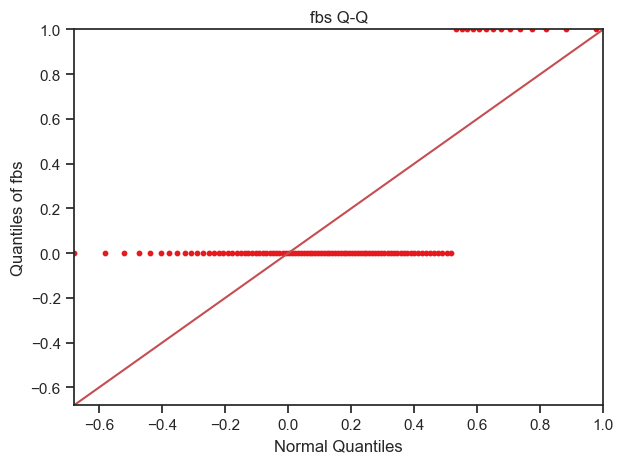

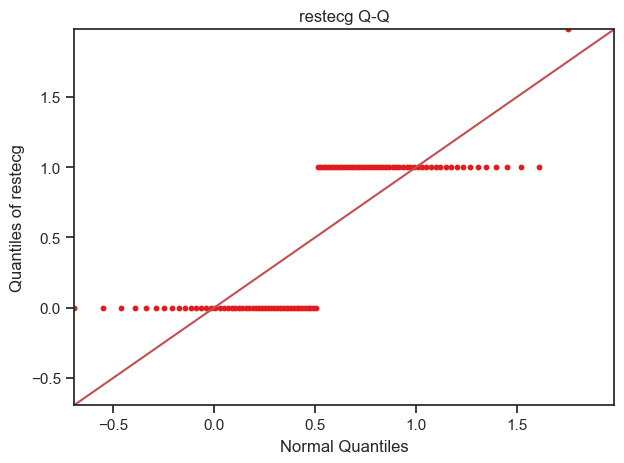

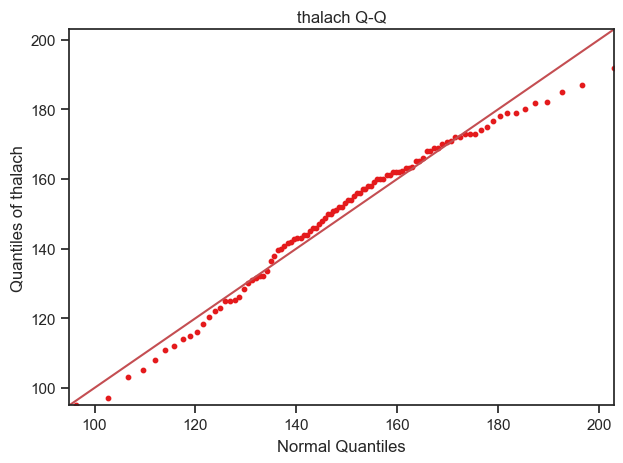

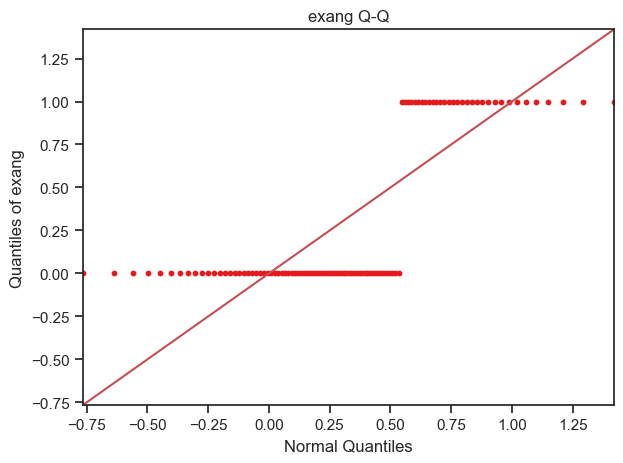

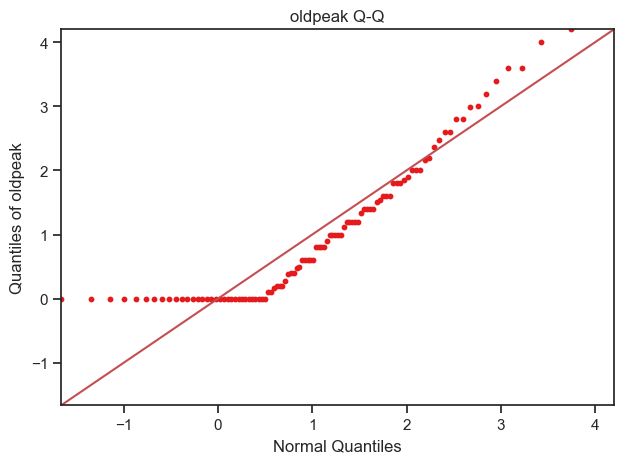

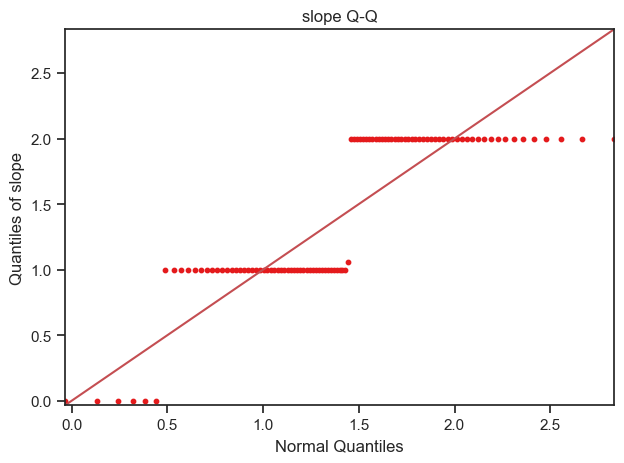

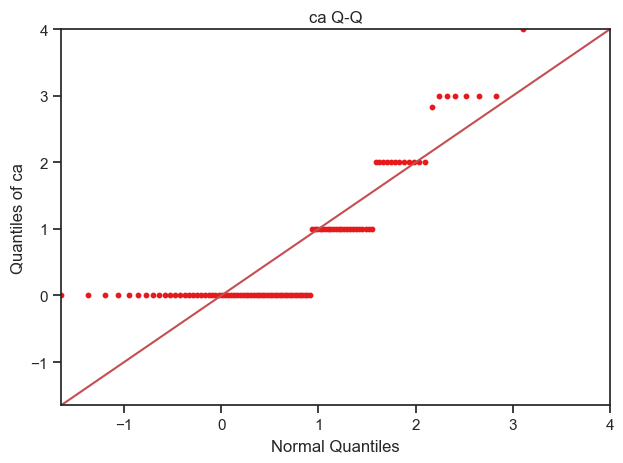

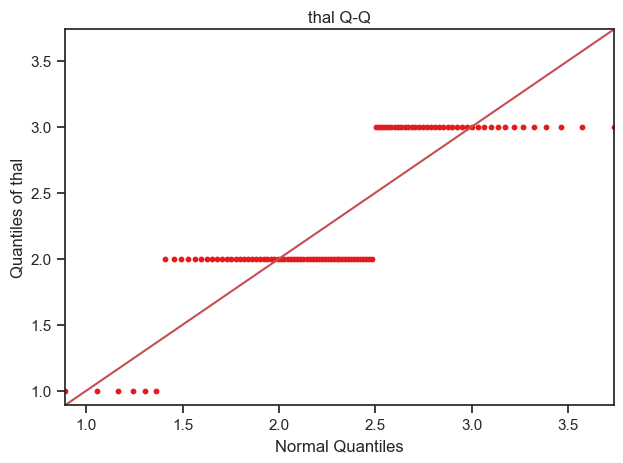

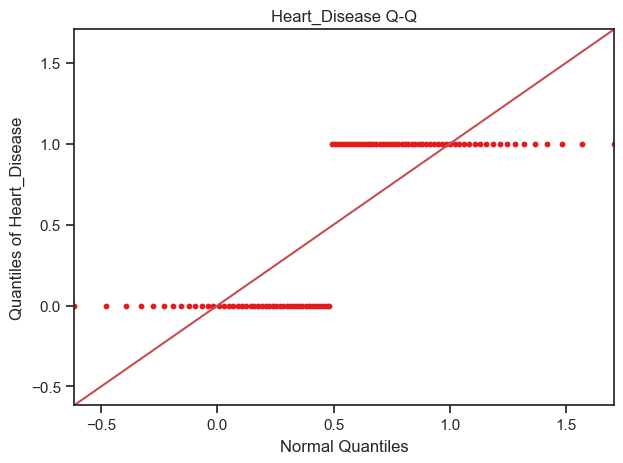

In [ ]:
%matplotlib inline

for column in df.columns:

    # Get rid of any non-numerical columns.
    if pd.api.types.is_numeric_dtype(df[column]):

        # Drop missing values in case it causes problems
        values = df[column].dropna()

        # Fit a normal distribution to THIS column's own scale.
        mean, std = values.mean(), values.std()

        # Make 99 percentiles, evenly spaced.
        probs = np.linspace(0.01, 0.99, 99)

        # Copies dataprep's method. take the sample of the quantiles.
        sample_qntls = values.quantile(probs)

        # Theoretical quantiles: what a perfectly normal distribution with
        # the datas mean and std would look like at each %
        theory_qntls = norm.ppf(probs, mean, std)

        # Combine both sets to find a shared min/max.
        vals = np.concatenate([sample_qntls, theory_qntls])
        lo, hi = vals.min(), vals.max()
        fig, ax = plt.subplots()

        # Plot sample quantiles with theoretical quantiles.
        ax.scatter(theory_qntls, sample_qntls, s=10)

        # Draw a diagonal line.
        ax.plot([lo, hi], [lo, hi], color="r")

        # Force both axes to the same range. Makes the 45 degrees fixed.
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)

        ax.set_title(f"{column} Q-Q")
        ax.set_xlabel("Normal Quantiles")
        ax.set_ylabel(f"Quantiles of {column}")

        plt.tight_layout()
        plt.show()

### Calcualte the Skewness and the kurtosis as values for better undertanding of the distribution of the continuous variables

In [ ]:
columns = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

print("Skewness:")
print(df[columns].skew())

print("\nExcess Kurtosis:")
print(df[columns].kurtosis())

Skewness:
age        -0.202463
trestbps    0.713768
chol        1.143401
thalach    -0.537410
oldpeak     1.269720
dtype: float64

Excess Kurtosis:
age        -0.542167
trestbps    0.929054
chol        4.505423
thalach    -0.061970
oldpeak     1.575813
dtype: float64


### As Q-Q Plots are not failry suitable for visualizs the distribution of the categorical variables.
### We can use bar charts for visualize categorical values

In [ ]:
# Checkt the counts and percentages
categorical_cols = [
    'sex', 'fbs', 'exang', 'Heart_Disease',
    'cp', 'restecg', 'thal', 'slope'
]

for col in categorical_cols:
    print((df[col].value_counts(normalize=True) * 100).round(2))

sex
1    68.32
0    31.68
Name: proportion, dtype: float64
fbs
0    85.15
1    14.85
Name: proportion, dtype: float64
exang
0    67.33
1    32.67
Name: proportion, dtype: float64
Heart_Disease
1    54.46
0    45.54
Name: proportion, dtype: float64
cp
0    47.19
2    28.71
1    16.50
3     7.59
Name: proportion, dtype: float64
restecg
1    50.17
0    48.51
2     1.32
Name: proportion, dtype: float64
thal
2    54.79
3    38.61
1     5.94
0     0.66
Name: proportion, dtype: float64
slope
2    46.86
1    46.20
0     6.93
Name: proportion, dtype: float64


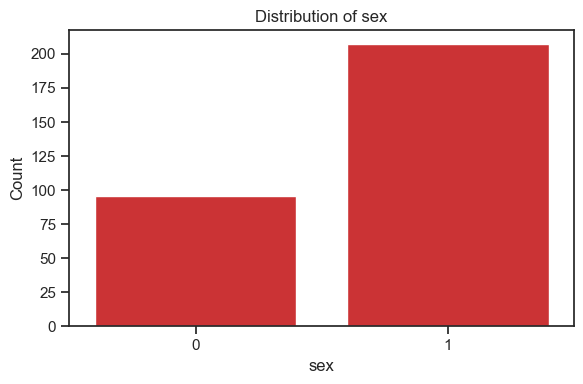

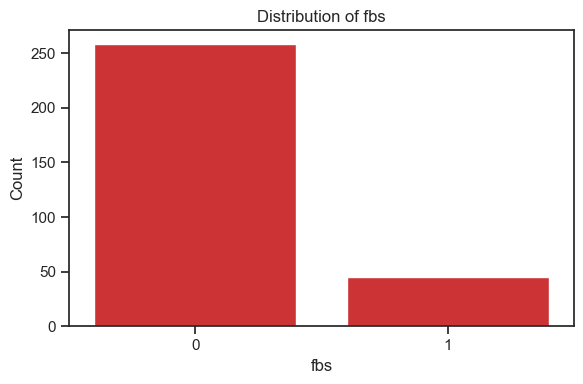

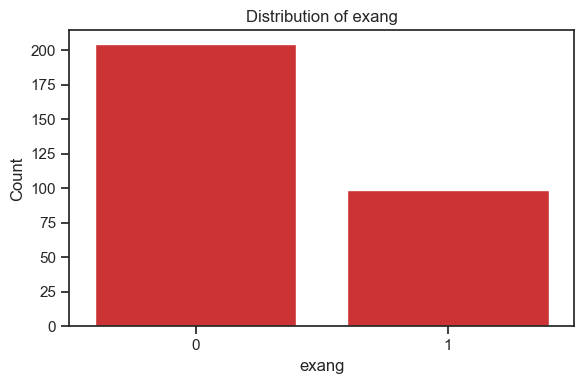

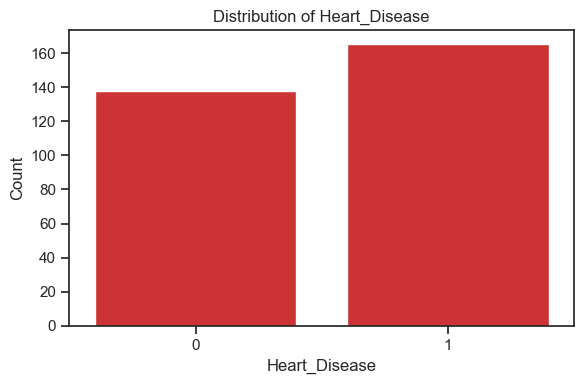

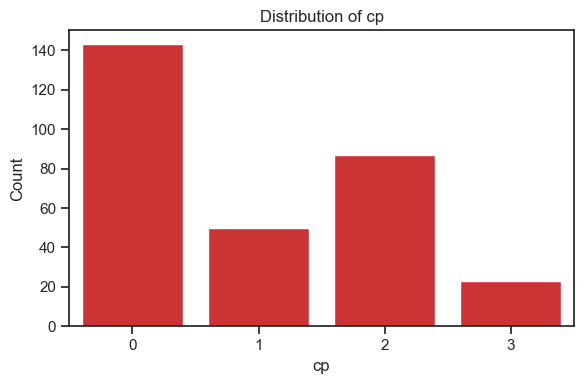

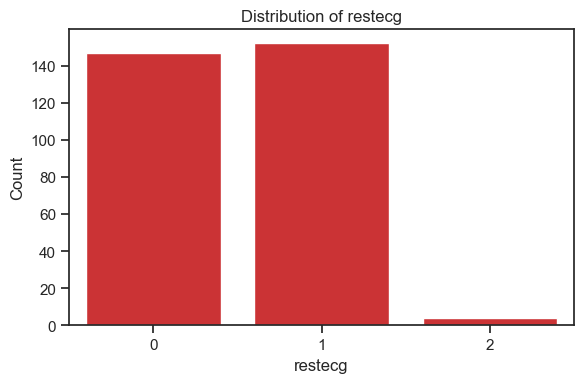

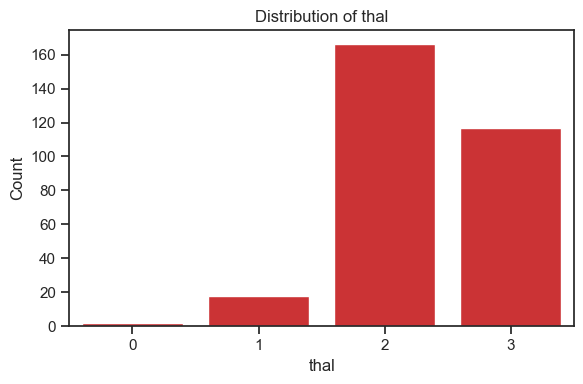

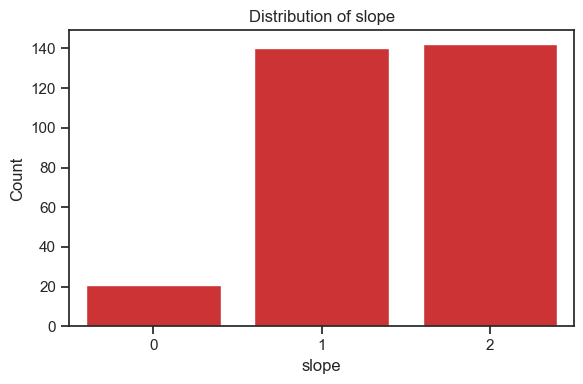

In [ ]:
# Visualize using bar-charts
for col in categorical_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col, order=sorted(df[col].dropna().unique()))
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()

### Check the Redundancy using Phik Matrix

In [ ]:
import phik
# compute phik-matrix values
phik_matrix = df.phik_matrix()

phik_matrix

interval columns not set, guessing: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'Heart_Disease']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Heart_Disease
age,1.000000,0.000000,0.172973,0.227790,0.000000,0.000000,0.343090,0.531103,0.096275,0.000000,0.116991,0.468660,0.034921,0.326927
sex,0.000000,1.000000,0.170223,0.000000,0.279960,0.000000,0.045242,0.220682,0.189501,0.000000,0.000000,0.092727,0.545244,0.408884
cp,0.172973,0.170223,1.000000,0.197552,0.000000,0.082051,0.083215,0.348636,0.660579,0.269722,0.200443,0.190650,0.455971,0.717290
trestbps,0.227790,0.000000,0.197552,1.000000,0.000000,0.163217,0.280138,0.215940,0.126076,0.228276,0.026315,0.101317,0.000000,0.000000
chol,0.000000,0.279960,0.000000,0.000000,1.000000,0.000000,0.218088,0.000000,0.000000,0.101050,0.000000,0.000000,0.000000,0.082487
fbs,0.000000,0.000000,0.082051,0.163217,0.000000,1.000000,0.018916,0.008486,0.000000,0.000000,0.040692,0.086595,0.138909,0.000000
restecg,0.343090,0.045242,0.083215,0.280138,0.218088,0.018916,1.000000,0.137949,0.034299,0.648368,0.315757,0.077633,0.000000,0.098589
thalach,0.531103,0.220682,0.348636,0.215940,0.000000,0.008486,0.137949,1.000000,0.501878,0.301837,0.452255,0.334070,0.289766,0.534085
exang,0.096275,0.189501,0.660579,0.126076,0.000000,0.000000,0.034299,0.501878,1.000000,0.284535,0.168350,0.140336,0.467828,0.620992
oldpeak,0.000000,0.000000,0.269722,0.228276,0.101050,0.000000,0.648368,0.301837,0.284535,1.000000,0.735935,0.320231,0.346782,0.437857


In [ ]:
# Based on the target variable - Generate the phik matrix for better analysis
phik_matrix['Heart_Disease'].sort_values(ascending=False)

Heart_Disease    1.000000
thal             0.730110
cp               0.717290
exang            0.620992
thalach          0.534085
oldpeak          0.437857
sex              0.408884
ca               0.398306
age              0.326927
slope            0.238242
restecg          0.098589
chol             0.082487
fbs              0.000000
trestbps         0.000000
Name: Heart_Disease, dtype: float64

### Visualize using a Heat-Map

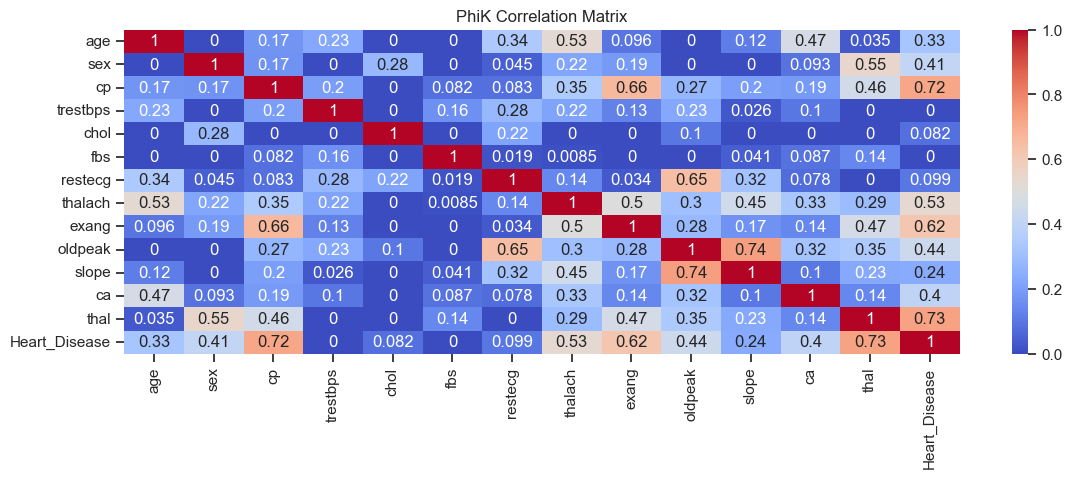

In [ ]:
plt.figure(figsize=(12, 4))

sns.heatmap(
    phik_matrix,
    annot=True,
    cmap="coolwarm"
)

plt.title("PhiK Correlation Matrix")
plt.show()

### Check the VIF test for the Multicollinearity

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor 

pd.set_option('display.float_format', lambda x: '%.1f' % x) 

import warnings
warnings.filterwarnings("ignore")

# load the data
df = pd.read_csv("Heart_Disease_fixed.csv")


# some missing values in the dataset, drop for VIF-test
df = df.dropna()

# perform X/y -split
# Everything EXCEPT target variable => support variable
X = df.drop("Heart_Disease", axis=1)

# Have only the target variable here (dependent variable)
y = df["Heart_Disease"]



# VIF dataframe 
# VIF = Variance Inflation Factor
vif_data = pd.DataFrame() 
vif_data["feature"] = X.columns 
  
# calculating VIF for each feature 
vif_data["VIF"] = [variance_inflation_factor(X.values, i) 
                          for i in range(len(X.columns))] 

# variables with high VIF-value 
# can mean multlicollinearity (variables providing same linear
vif_data.sort_values(by="VIF", ascending=False)

,feature,VIF
9,oldpeak,1.7
10,slope,1.6
7,thalach,1.6
0,age,1.4
8,exang,1.4
2,cp,1.3
11,ca,1.2
3,trestbps,1.2
1,sex,1.2
4,chol,1.2


### FInd the Cardinality with the unique values

In [ ]:
# Count unique values in each column
cardinality = df.nunique()

# Calculate percentage of unique values
unique_percentage = (df.nunique() / len(df)) * 100

# Display results
print(pd.DataFrame({
    'Unique Values': cardinality,
    'Unique Percentage (%)': unique_percentage.round(2)
}))

               Unique Values  Unique Percentage (%)
age                  41               13.5         
sex                   2                0.7         
cp                    4                1.3         
trestbps             49               16.2         
chol                152               50.2         
fbs                   2                0.7         
restecg               3                1.0         
thalach              91               30.0         
exang                 2                0.7         
oldpeak              40               13.2         
slope                 3                1.0         
ca                    5                1.6         
thal                  4                1.3         
Heart_Disease         2                0.7         


### For Identify the Major Trends
#### Use box plots to compare the distributions of numerical features between people with and without heart disease.

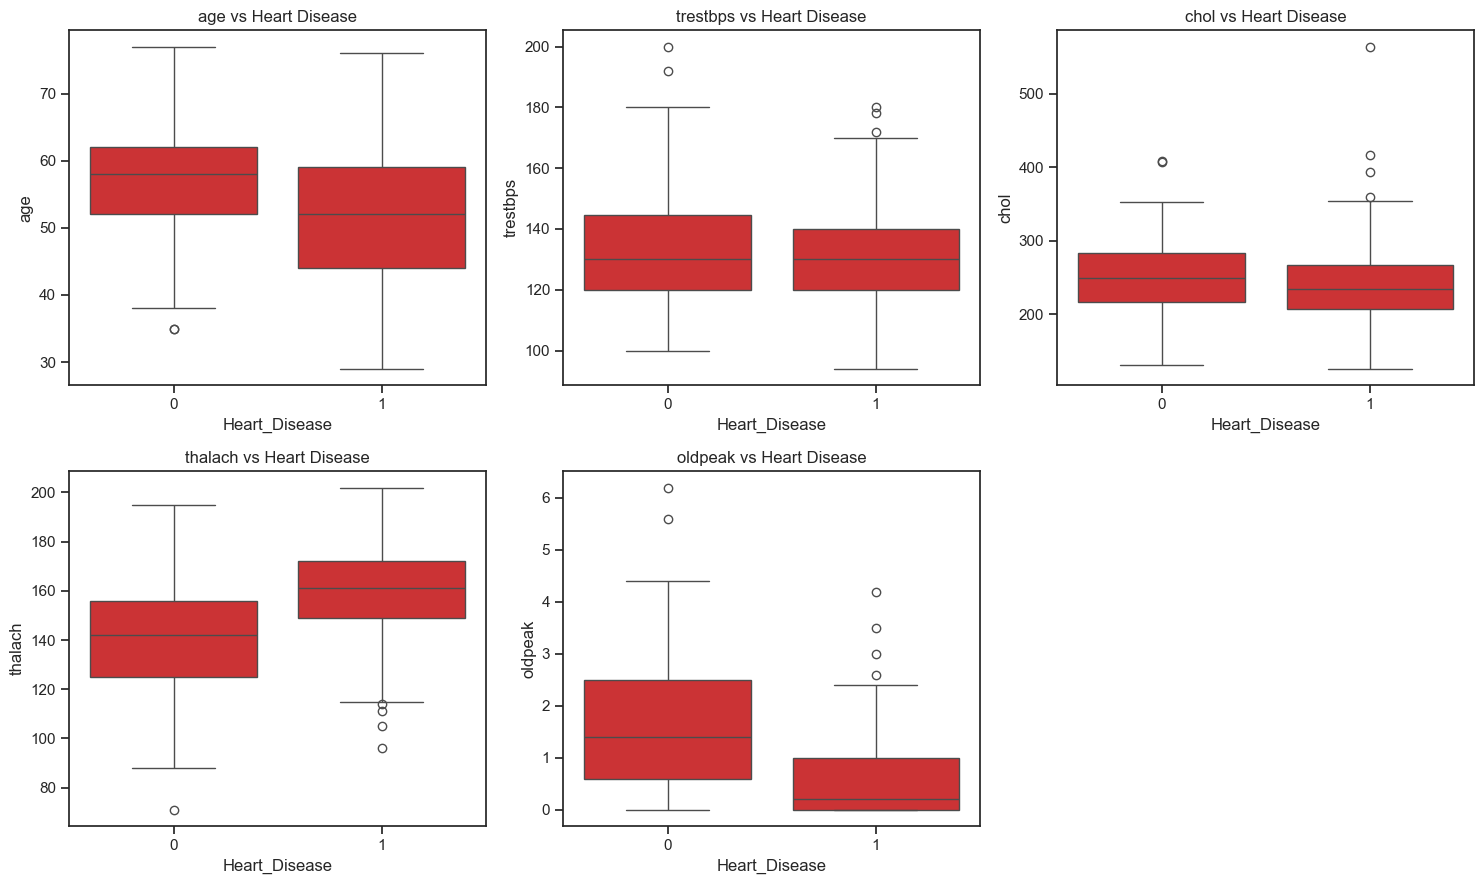

In [36]:
# Visualize numerical columns using box plots
numerical_cols = [
    'age', 'trestbps', 'chol',
    'thalach', 'oldpeak'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(
        data=df,
        x='Heart_Disease',
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(f'{col} vs Heart Disease')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

### Use Count Plots to compare heart disease outcomes across categories.        

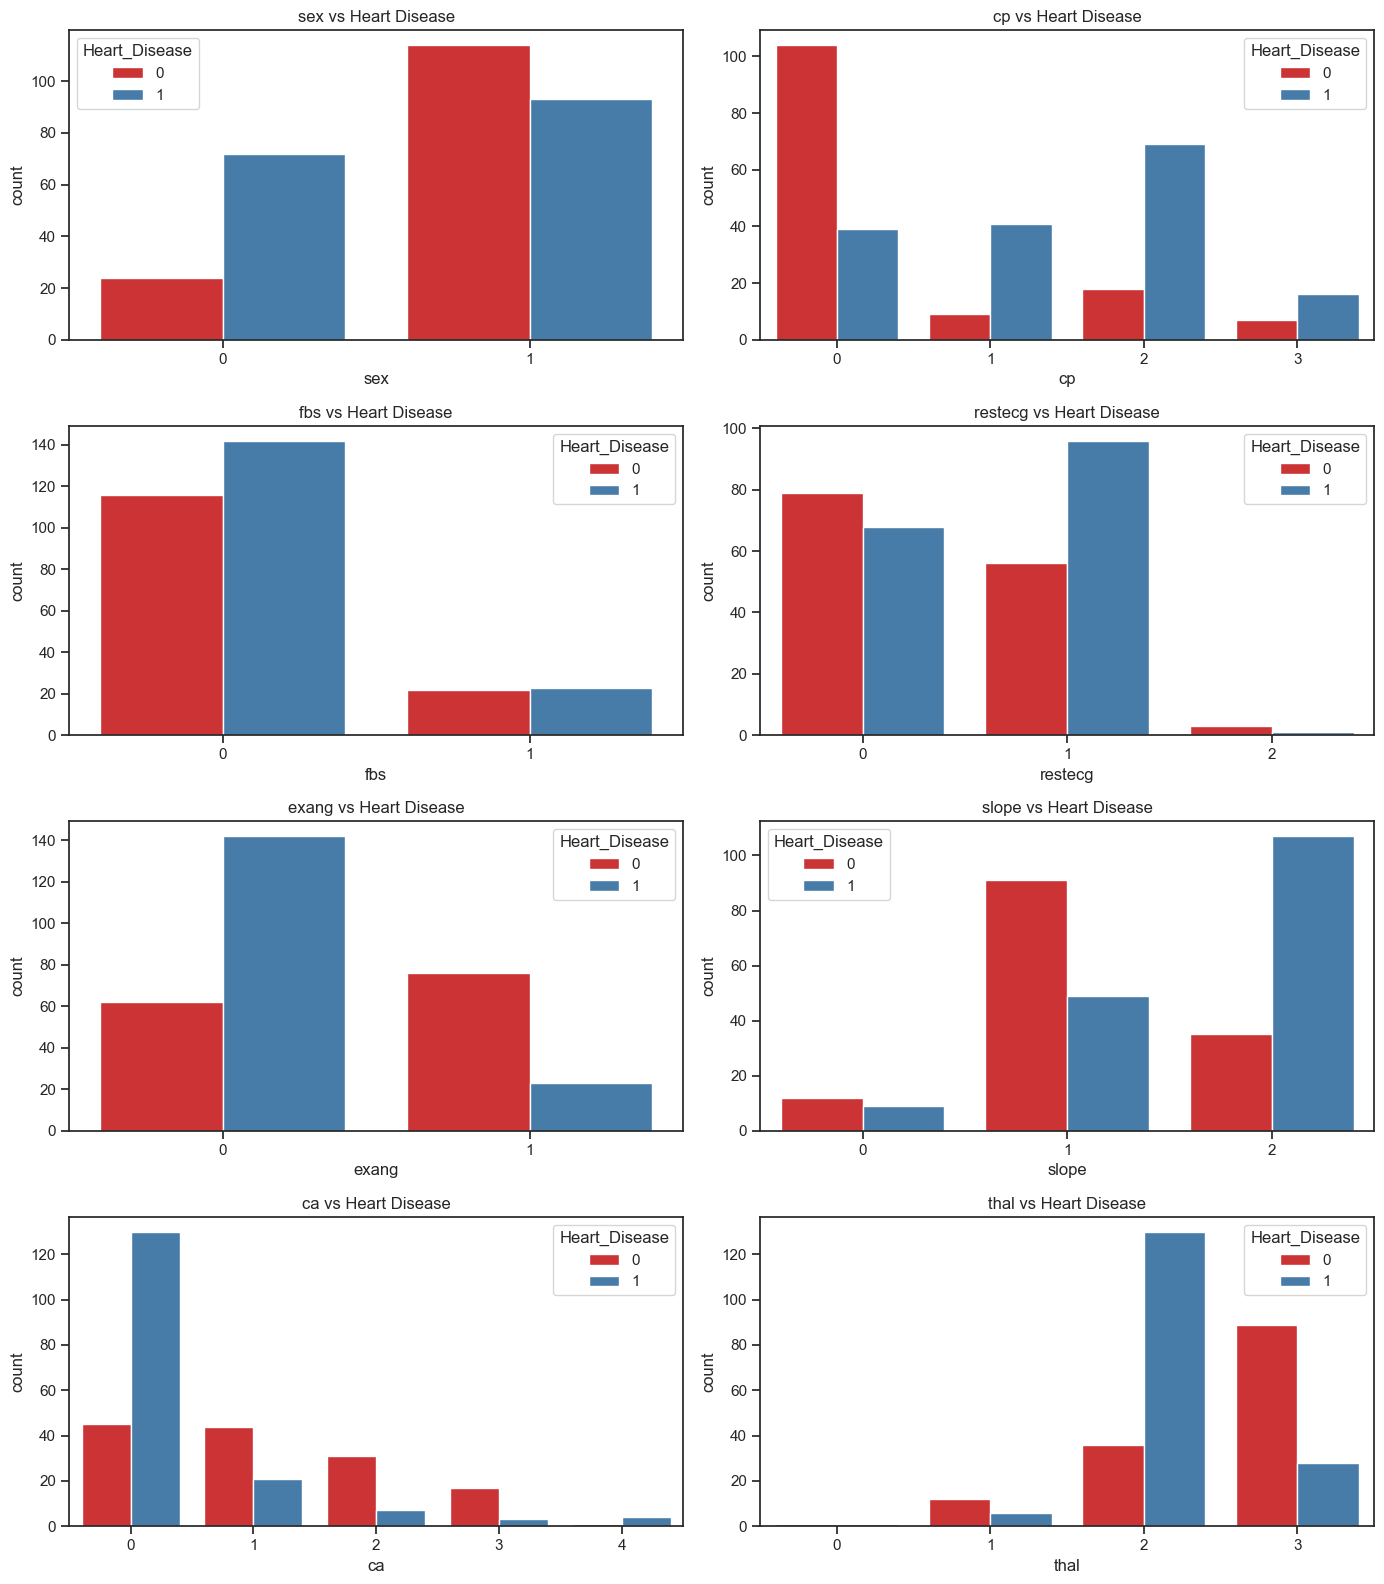

In [37]:
categorical_cols = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=df,
        x=col,
        hue='Heart_Disease',
        ax=axes[i]
    )
    axes[i].set_title(f'{col} vs Heart Disease')

plt.tight_layout()
plt.show()

### Visualizing treds with scatter plots - numerical values


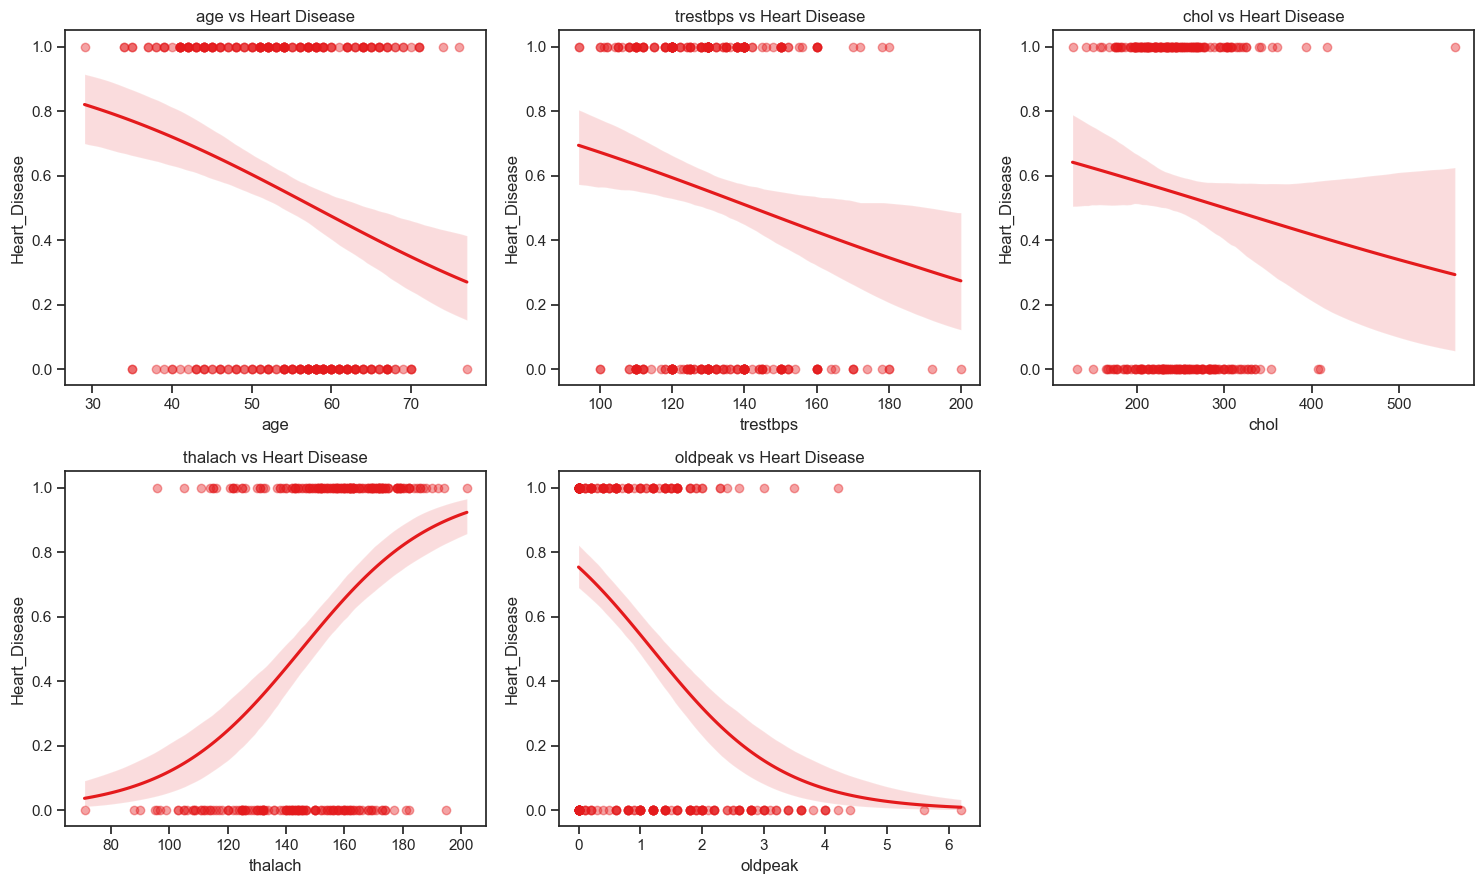

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.regplot(
        data=df,
        x=col,
        y='Heart_Disease',
        logistic=True,
        scatter_kws={'alpha': 0.4},
        ax=axes[i]
    )
    axes[i].set_title(f'{col} vs Heart Disease')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

### Analysis the Overlapping in the Dataset


#### Pair plot is useful for identifying overlap between people with and without heart disease, relationships between continuous features

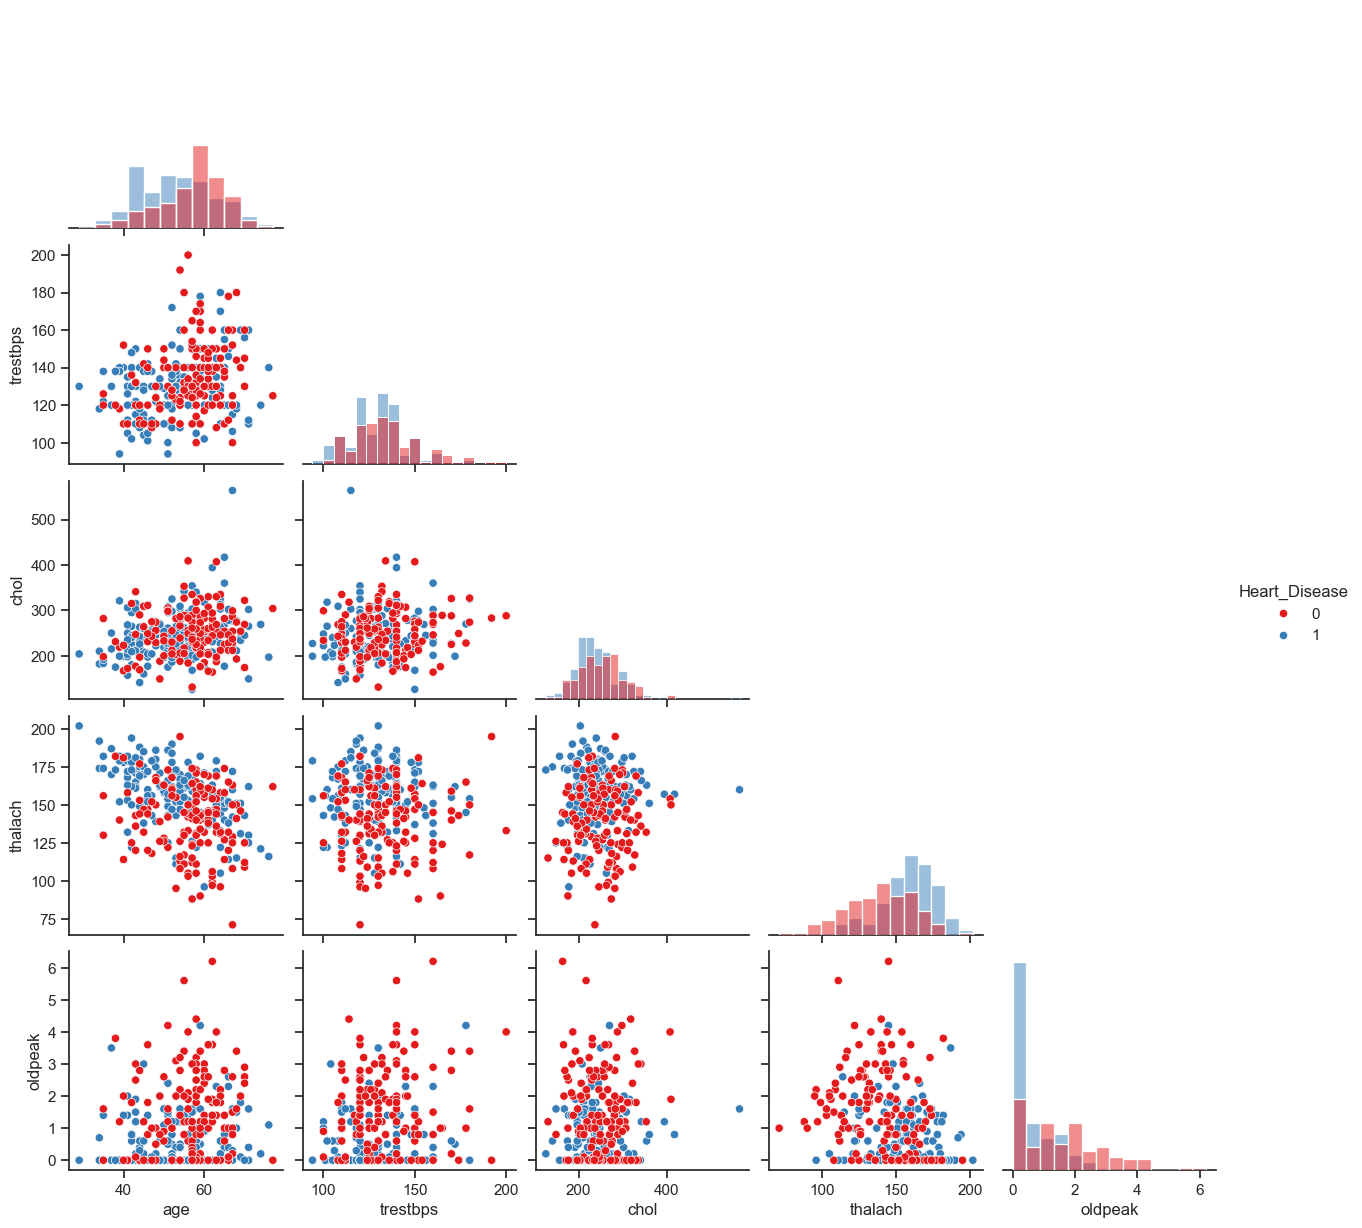

In [40]:
continuous_cols = [
    'age', 'trestbps', 'chol',
    'thalach', 'oldpeak'
]

sns.pairplot(
    df[continuous_cols + ['Heart_Disease']],
    hue='Heart_Disease',
    diag_kind='hist',
    corner=True
)

plt.show()

### Detect the Ouliers using Isolation Forest

In [ ]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05) 
df = pd.read_csv("Heart_Disease_fixed.csv")

# fit isolation forest
y_pred = iso.fit_predict(df)

# separate outliers and inliers into separate DataFrames
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

Inliers: 287
Outliers: 16


In [43]:
outliers

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Heart_Disease
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
85,67,0,2,115,564,0,0,160,0,1.6,1,0,3,1
101,59,1,3,178,270,0,0,145,0,4.2,0,0,3,1
203,68,1,2,180,274,1,0,150,1,1.6,1,0,3,0
204,62,0,0,160,164,0,0,145,0,6.2,0,3,3,0
215,43,0,0,132,341,1,0,136,1,3.0,1,0,3,0
220,63,0,0,150,407,0,0,154,0,4.0,1,3,3,0
223,56,0,0,200,288,1,0,133,1,4.0,0,2,3,0
247,66,1,1,160,246,0,1,120,1,0.0,1,3,1,0
259,38,1,3,120,231,0,1,182,1,3.8,1,0,3,0


### Visulaize both ouliers and Inliers with numerical values using scater plots

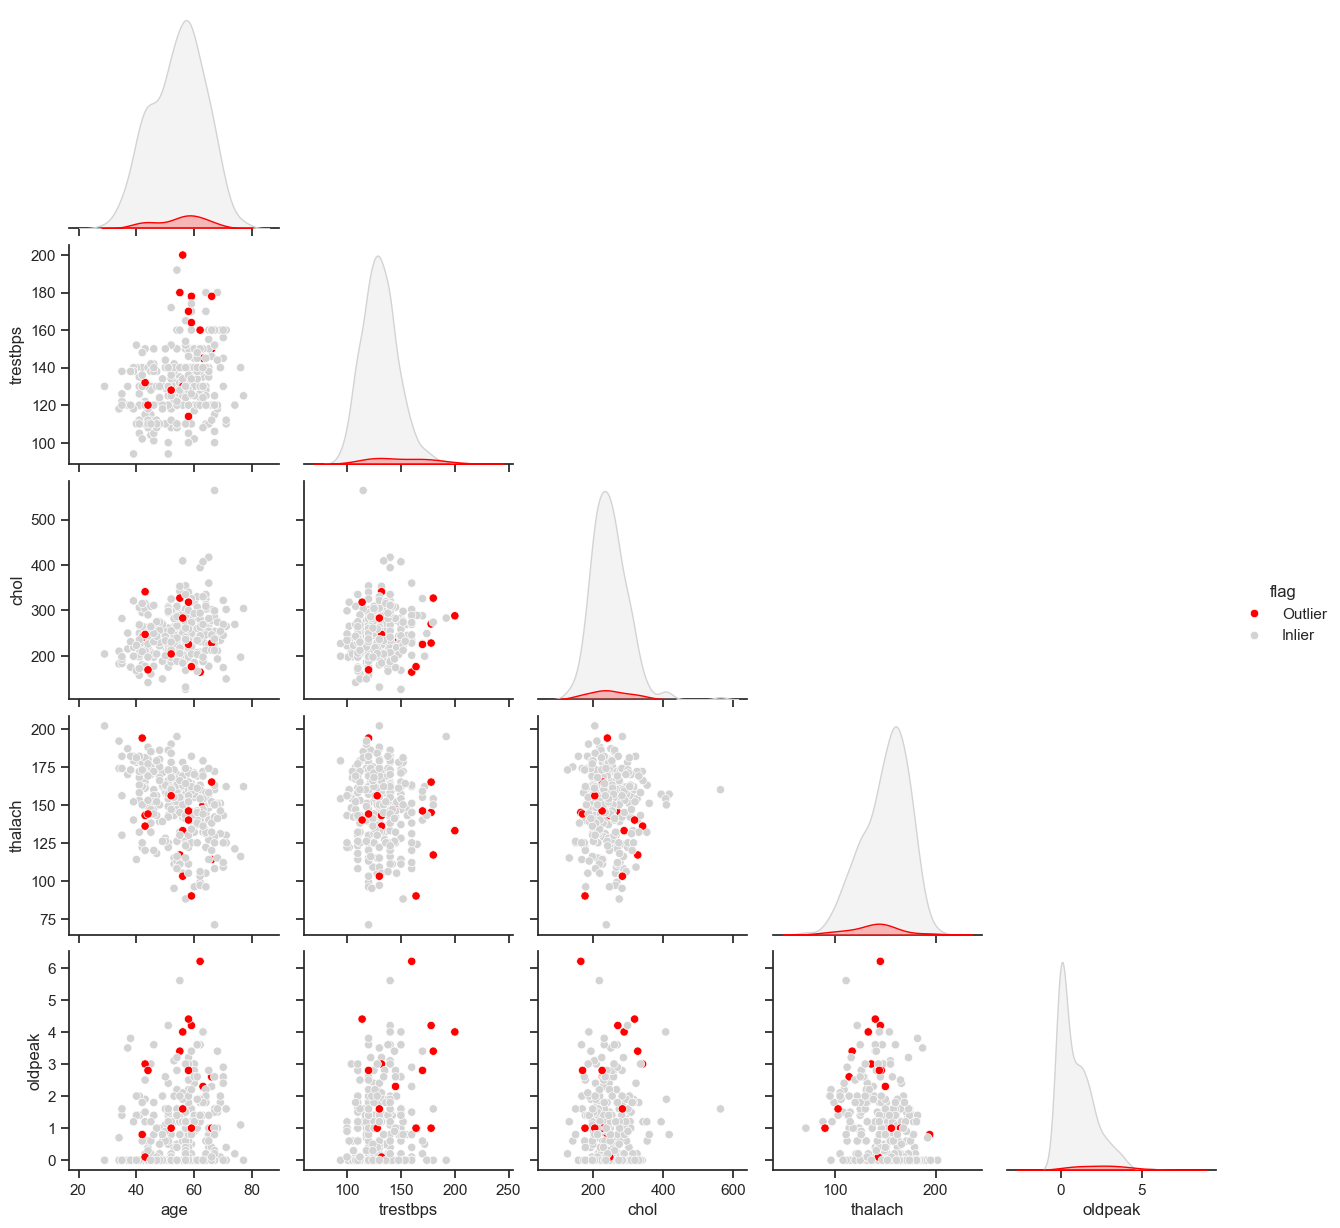

In [ ]:
# ChatGpt helps to generate this code
X = df.drop(columns="Heart_Disease")
iso = IsolationForest(contamination=0.05, random_state=42)
df["flag"] = iso.fit_predict(X)
df["flag"] = df["flag"].map({1: "Inlier", -1: "Outlier"})

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
sns.pairplot(df[num_cols + ["flag"]], hue="flag",
             palette={"Inlier": "lightgrey", "Outlier": "red"},
             corner=True)
plt.show()

### Detect the Noise in data set using continous variables with MAD

In [47]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split

# load data
df = pd.read_csv("Heart_Disease_fixed.csv")

# use preferably the most impactful continous variable towards the target variable
variable = 'thalach'
# Calculate the median
median = df[variable].median()

# Calculate MAD
mad = np.median(np.abs(df[variable] - median))

# Define a threshold for noise detection
threshold = 2.0 * mad

# Detect noise
noise = df[np.abs(df[variable] - median) > threshold]

inliers = df.drop(noise.index)

print("Detected noise using MAD:")
noise

Detected noise using MAD:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Heart_Disease
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
17,66,0,3,150,226,0,1,114,0,2.6,0,0,2,1
32,44,1,1,130,219,0,0,188,0,0.0,2,0,2,1
48,53,0,2,128,216,0,0,115,0,0.0,2,0,0,1
56,48,1,0,122,222,0,0,186,0,0.0,2,0,2,1
57,45,1,0,115,260,0,0,185,0,0.0,2,0,2,1
62,52,1,3,118,186,0,0,190,0,0.0,1,0,1,1
72,29,1,1,130,204,0,0,202,0,0.0,2,0,2,1
73,51,1,0,140,261,0,0,186,1,0.0,2,0,2,1
78,52,1,1,128,205,1,1,184,0,0.0,2,0,2,1


#### Determine the relatiosnhips using Pearson Correlation Matrix

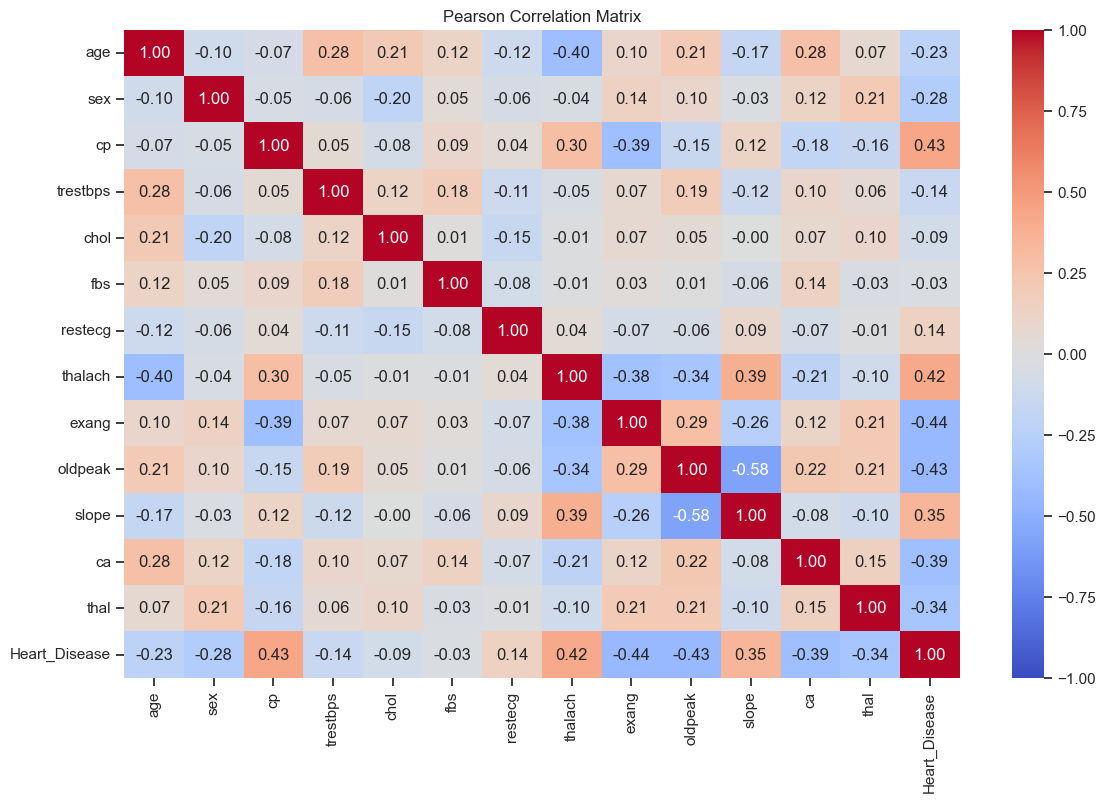

In [48]:
corr = df.corr(method="pearson")

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson Correlation Matrix")
plt.show()

### We can use Fisher Score to find whcih supporting features are good at seperating the target variable

<Axes: >

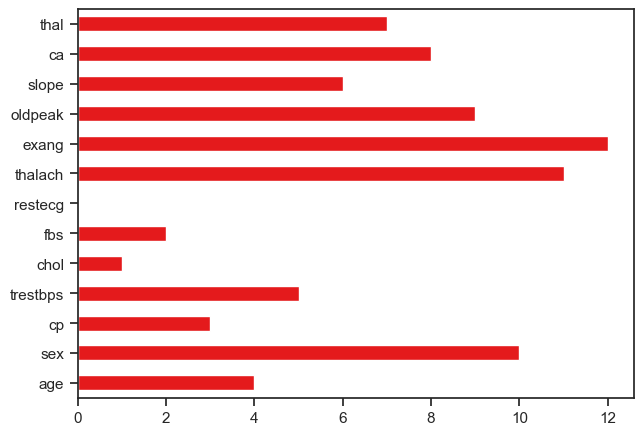

In [51]:
# load the data
df = pd.read_csv("Heart_Disease_fixed.csv")

# perform X/y -split
# everything EXCEPT target variable => support variable
X = df.drop("Heart_Disease", axis=1)

# have only the target variable here (dependent variable)
y = df["Heart_Disease"]

from skfeature.function.similarity_based import fisher_score

# get the fisher's score rankings 
ranks = fisher_score.fisher_score(X.values, y.values)

# create a pandas DataFrame for easier interpretation
feat_importances = pd.Series(ranks, X.columns)
feat_importances.plot(kind='barh')

### Apriori - use to analyze multiple categorical variables

In [63]:
from mlxtend.frequent_patterns import apriori

# load the data
df = pd.read_csv("Heart_Disease_fixed.csv")

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Heart_Disease
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [64]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'Heart_Disease'],
      dtype='object')

In [55]:
# As apriori only supports categorical variables
# We extract the categorical columns from the dataset
df = df.drop(['age','trestbps','chol','thalach','oldpeak'], axis=1)
df.head()


,sex,cp,fbs,restecg,exang,slope,ca,thal,Heart_Disease
0,1,3,1,0,0,0,0,1,1
1,1,2,0,1,0,0,0,2,1
2,0,1,0,0,0,2,0,2,1
3,1,1,0,1,0,2,0,2,1
4,0,0,0,1,1,2,0,2,1


In [56]:
df.columns

Index(['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal',
       'Heart_Disease'],
      dtype='object')

In [71]:
category_columns = [
    'sex', 'cp', 'fbs', 'restecg', 'exang',
    'slope', 'ca', 'thal', 'Heart_Disease'
]

categories_only_df = df[category_columns]

# Convert categories into binary columns
categories_encoded = pd.get_dummies(
    categories_only_df.astype('category'),
    dtype=bool
)

frequent_itemsets = apriori(categories_encoded, min_support=0.0001, use_colnames=True)

# Filter for itemsets with low support, and sort by lowest score
# adjust the the decimal to increase or decrease threshold

rare_itemsets = frequent_itemsets[frequent_itemsets['support'] < 0.005]
rare_itemsets.sort_values("support")


rare_itemsets

,support,itemsets
45,0.0,"(sex_0, thal_0)"
46,0.0,"(sex_0, thal_1)"
59,0.0,"(restecg_2, sex_1)"
70,0.0,"(thal_0, sex_1)"
90,0.0,"(cp_0, ca_4)"
...,...,...
30020,0.0,"(fbs_0, slope_2, Heart_Disease_1, ca_0, thal_3, sex_1, restecg_1, cp_3, exang_1)"
30021,0.0,"(thal_1, Heart_Disease_1, exang_0, ca_0, slope_0, sex_1, cp_3, fbs_1, restecg_0)"
30022,0.0,"(thal_2, ca_1, Heart_Disease_0, exang_0, sex_1, slope_1, cp_3, fbs_1, restecg_0)"
30023,0.0,"(thal_2, ca_1, Heart_Disease_1, exang_0, sex_1, slope_1, cp_3, fbs_1, restecg_0)"
